# 05 -- Scenario planning and price optimisation

Built on the Phase 3 elasticities (`beverage_demand.scenario`). Assumptions: constant elasticity,
no competitor price reaction, fixed unit cost. Use as directional guidance, not a forecast.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
from beverage_demand.cli import format_scenario
from beverage_demand.scenario.simulate import simulate

## "If we drop Coke 2L by 10% for 4 weeks, what happens?"

In [2]:
print(format_scenario(simulate("Coke", "2L", -10, weeks=4)))

Scenario: Coke | 2L regular price $1.66 -> $1.49
Assumes constant elasticities and no competitor price reaction; ranges from elasticity standard errors.
            Series       Role Units (base) Units (scenario) Units 90% range Volume Revenue Gross margin GM $ change
         Coke | 2L     target       70,004          101,153  99,823-102,475 +44.5%  +30.0%        +9.1%      +4,322
          7Up | 2L competitor       17,896           17,530   17,435-17,619  -2.0%   -2.0%        -2.0%        -184
    Diet Coke | 2L competitor       59,363           59,740   59,269-60,172  +0.6%   +0.6%        +0.6%        +256
   Diet Pepsi | 2L competitor       29,640           28,816   28,655-28,977  -2.8%   -2.8%        -2.8%        -320
        Pepsi | 2L competitor       46,037           44,703   44,472-44,951  -2.9%   -2.9%        -2.9%        -555
Private Label | 2L competitor       94,016           91,156   90,515-91,796  -3.0%   -3.0%        -3.0%      -1,479


**So what:** A 10% cut on Coke 2L lifts its volume by about 45% and revenue by about 30%, but gross
margin rises much less because every unit now earns less. Roughly 2-3% of the volume of Pepsi,
Diet Pepsi, 7Up and private label 2L moves to Coke.

In [3]:
print(format_scenario(simulate("Pepsi", "24pk can", -15, promo_type="S", weeks=2)))

Scenario: Pepsi | 24pk can regular price $8.41 -> $7.15
Assumes constant elasticities and no competitor price reaction; ranges from elasticity standard errors.
                  Series       Role Units (base) Units (scenario) Units 90% range  Volume Revenue Gross margin GM $ change
        Pepsi | 24pk can     target        4,302           22,544   21,478-23,754 +424.1% +345.5%       -28.5%      -1,791
          7Up | 24pk can competitor          718              694         686-701   -3.4%   -3.4%        -3.4%         -28
         Coke | 24pk can competitor        3,517            3,314     3,279-3,350   -5.8%   -5.8%        -5.8%        -101
    Diet Coke | 24pk can competitor        2,157            1,973     1,950-1,998   -8.5%   -8.5%        -8.5%         -90
Private Label | 24pk can competitor          936            1,022     1,004-1,039   +9.2%   +9.2%        +9.2%        +171


## Margin-maximising regular price

In [4]:
pd.read_csv(results("price_optimization.csv"))[["series", "elasticity", "regular_price", "unit_cost", "current_margin_pct", "optimal_price", "price_change_pct", "margin_uplift_pct", "at_bound"]]

,series,elasticity,regular_price,unit_cost,current_margin_pct,optimal_price,price_change_pct,margin_uplift_pct,at_bound
0,Pepsi | 24pk can,-6.209,8.411,6.950,0.174,8.284,-0.015,3.538e-03,False
1,Diet Pepsi | 24pk can,-5.710,8.411,6.950,0.174,8.426,0.002,4.256e-05,False
2,Diet Coke | 24pk can,-5.642,8.378,7.890,0.058,9.590,0.145,6.267e-01,False
3,Coke | 24pk can,-5.518,8.391,7.890,0.060,9.637,0.148,6.246e-01,False
4,7Up | 24pk can,-5.021,8.413,7.250,0.138,9.053,0.076,7.286e-02,False
5,Private Label | 24pk can,-4.628,5.942,3.950,0.335,5.039,-0.152,1.723e-01,False
6,Pepsi | 2L,-4.041,1.657,1.241,0.251,1.649,-0.005,1.422e-04,False
7,Diet Pepsi | 2L,-3.890,1.630,1.242,0.238,1.672,0.025,3.771e-03,False
8,Coke | 2L,-3.491,1.658,0.981,0.408,1.375,-0.171,1.187e-01,False
9,Diet Coke | 2L,-3.325,1.660,0.981,0.409,1.403,-0.155,8.751e-02,False


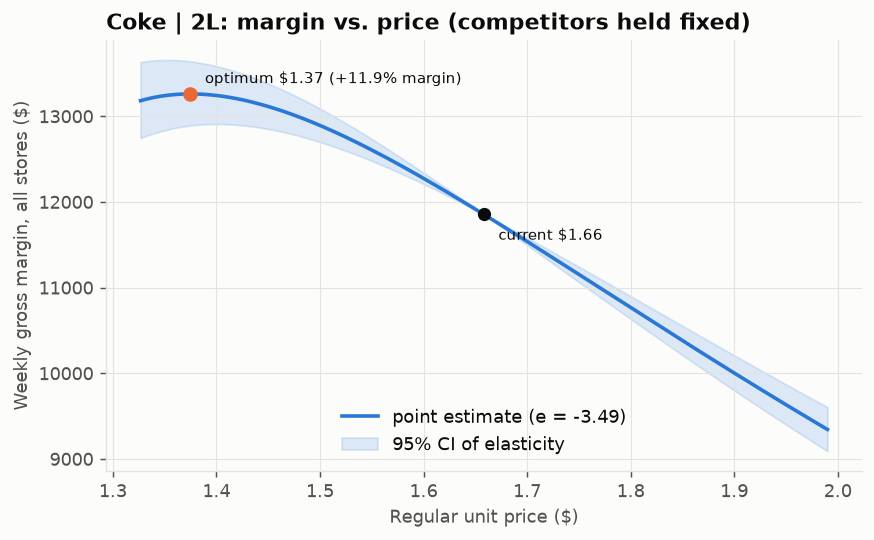

In [5]:
Image(filename=str(figure("price_optimization_curve.png")))

**So what:** With constant elasticity the best price follows the textbook rule
`price = cost x e / (1 + e)`. For Coke 2L that points to a lower regular price than today, but this
should be read with care: the elasticities are measured mostly from short temporary promotions,
which overstate how shoppers would react to a *permanent* price change (stock-piling), and
competitors would likely respond. The value of this tool is ranking options and sizing trade-offs,
not setting the shelf price on its own.